# Q-Learning on CartPole

Tabular Q-learning with a discretized state space on OpenAI Gym's CartPole-v1, including reward tracking over episodes.

In [ ]:
import gym
import matplotlib.pyplot as plt

# Loading the CartPole environment
env = gym.make("CartPole-v1")
state = env.reset()

# state space and action space
print("State Space:", env.observation_space)
print("Action Space:", env.action_space)

# interacting with the environment
for _ in range(10):
    action = env.action_space.sample()  # Random action
    next_state, reward, done, info = env.step(action)
    print(f"Next State: {next_state}, Reward: {reward}, Done: {done}")
    if done:
        break
env.close()


State Space: Box([-4.8000002e+00 -3.4028235e+38 -4.1887903e-01 -3.4028235e+38], [4.8000002e+00 3.4028235e+38 4.1887903e-01 3.4028235e+38], (4,), float32)
Action Space: Discrete(2)
Next State: [ 0.00817597  0.1613844  -0.03163765 -0.2605619 ], Reward: 1.0, Done: False
Next State: [ 0.01140365  0.35694337 -0.03684889 -0.5630535 ], Reward: 1.0, Done: False
Next State: [ 0.01854252  0.5525625  -0.04810996 -0.86711407], Reward: 1.0, Done: False
Next State: [ 0.02959377  0.74830496 -0.06545224 -1.1745269 ], Reward: 1.0, Done: False
Next State: [ 0.04455987  0.94421357 -0.08894278 -1.4869899 ], Reward: 1.0, Done: False
Next State: [ 0.06344415  1.1402996  -0.11868258 -1.8060709 ], Reward: 1.0, Done: False
Next State: [ 0.08625013  0.94668555 -0.15480399 -1.5525037 ], Reward: 1.0, Done: False
Next State: [ 0.10518384  0.7537215  -0.18585406 -1.3118497 ], Reward: 1.0, Done: False
Next State: [ 0.12025827  0.56137437 -0.21209106 -1.0826247 ], Reward: 1.0, Done: True


/usr/local/lib/python3.10/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.10/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.10/dist-packages/gym/utils/passive_env_checker.py:241: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


In [ ]:
import gym
import numpy as np

# Creating the environment
env = gym.make("CartPole-v1")

# Discretize the state space
num_bins = [6, 6, 6, 6]  # Number of bins for each state feature
state_bins = [
    np.linspace(-4.8, 4.8, num_bins[0] - 1),
    np.linspace(-4, 4, num_bins[1] - 1),
    np.linspace(-0.418, 0.418, num_bins[2] - 1),
    np.linspace(-3.5, 3.5, num_bins[3] - 1),
]

def discretize_state(state):
    """Convert continuous state into a discrete one."""
    discretized_state = []
    for i, feature in enumerate(state):
        discretized_state.append(np.digitize(feature, state_bins[i]))
    return tuple(discretized_state)

# Initializing Q-table
state_space_size = tuple(num_bins)
action_space_size = env.action_space.n
q_table = np.zeros(state_space_size + (action_space_size,))

# Parameters
learning_rate = 0.1
discount_factor = 0.99
epsilon = 1.0
epsilon_decay = 0.995
min_epsilon = 0.01
episodes = 500

# Storing rewards for each episode
rewards_per_episode = []

for episode in range(episodes):
    state = discretize_state(env.reset())
    done = False
    total_reward = 0

    while not done:
        # Epsilon-greedy policy
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state])

        next_state, reward, done, _ = env.step(action)
        next_state = discretize_state(next_state)

        # Update Q-value
        q_table[state + (action,)] += learning_rate * (
            reward + discount_factor * np.max(q_table[next_state]) - q_table[state + (action,)]
        )

        state = next_state
        total_reward += reward

    rewards_per_episode.append(total_reward)  # Append total reward for this episode
    epsilon = max(min_epsilon, epsilon * epsilon_decay)
    print(f"Episode: {episode + 1}, Total Reward: {total_reward}")

env.close()


Episode: 1, Total Reward: 14.0
Episode: 2, Total Reward: 27.0
Episode: 3, Total Reward: 19.0
Episode: 4, Total Reward: 13.0
Episode: 5, Total Reward: 34.0
Episode: 6, Total Reward: 25.0
Episode: 7, Total Reward: 13.0
Episode: 8, Total Reward: 47.0
Episode: 9, Total Reward: 75.0
Episode: 10, Total Reward: 19.0
Episode: 11, Total Reward: 14.0
Episode: 12, Total Reward: 11.0
Episode: 13, Total Reward: 56.0
Episode: 14, Total Reward: 12.0
Episode: 15, Total Reward: 34.0
Episode: 16, Total Reward: 43.0
Episode: 17, Total Reward: 14.0
Episode: 18, Total Reward: 14.0
Episode: 19, Total Reward: 44.0
Episode: 20, Total Reward: 94.0
Episode: 21, Total Reward: 12.0
Episode: 22, Total Reward: 19.0
Episode: 23, Total Reward: 21.0
Episode: 24, Total Reward: 17.0
Episode: 25, Total Reward: 27.0
Episode: 26, Total Reward: 11.0
Episode: 27, Total Reward: 18.0
Episode: 28, Total Reward: 30.0
Episode: 29, Total Reward: 19.0
Episode: 30, Total Reward: 18.0
Episode: 31, Total Reward: 50.0
Episode: 32, Tota

In [ ]:
def evaluate_agent(env, q_table, episodes=100):
    total_rewards = []

    for _ in range(episodes):
        state = discretize_state(env.reset())
        done = False
        episode_reward = 0

        while not done:
            action = np.argmax(q_table[state])
            next_state, reward, done, _ = env.step(action)
            next_state = discretize_state(next_state)
            episode_reward += reward
            state = next_state

        total_rewards.append(episode_reward)

    print(f"Average Reward over {episodes} episodes: {np.mean(total_rewards)}")

evaluate_agent(env, q_table)


Average Reward over 100 episodes: 54.84


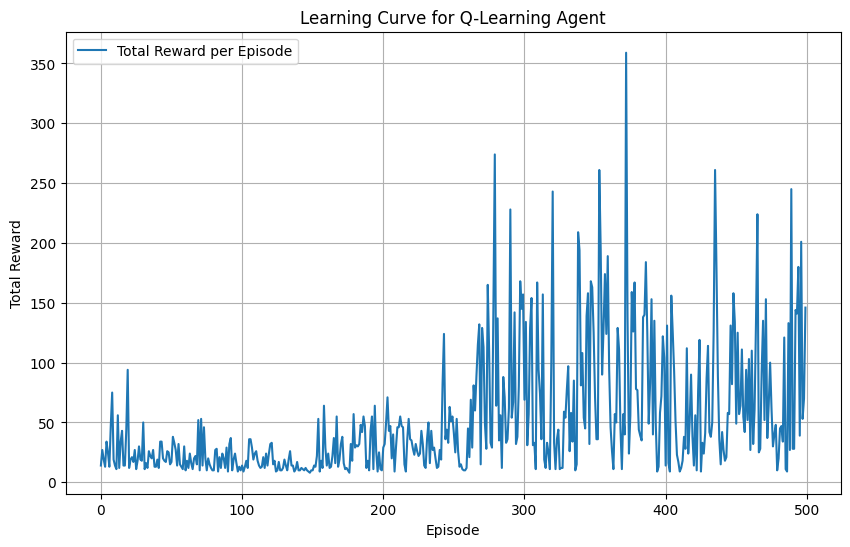

In [ ]:
# Ploting learning curve
plt.figure(figsize=(10, 6))
plt.plot(rewards_per_episode, label="Total Reward per Episode")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Learning Curve for Q-Learning Agent")
plt.legend()
plt.grid()
plt.show()
